In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1
    
    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    
    print("作業ディレクトリを該当章へ移動中...")
    %cd /content/{repo_name}/2
    print("✅ 準備完了！このまま下のセルを実行して学習を開始できます。")
else:
    _repo_root = Path.cwd().parent if Path.cwd().name == '2' else Path.cwd()
    if str(_repo_root) not in sys.path:
        sys.path.insert(0, str(_repo_root))


# 第2章 EDK II入門とメモリマップ — 演習問題 (*Chapter 2 Comprehensive Exercises*)

名著『**ゼロからのOS自作入門**』（内田公太 著）第2章「EDK II入門とメモリマップ」で学んだ、EDK IIビルドシステム（`.dec`, `.dsc`, `.inf`）、`UefiMain`、物理アドレス空間・RAM vs MMIO、`EFI_MEMORY_DESCRIPTOR` 構造体、`GetMemoryMap()` と `MapKey`、メモリマップCSV保存、空きRAM集計と再利用可能メモリ、64-bitポインタ変数とポインタ算術、構造体自然アライメントと二重ポインタ（`void**`）の全理論と実装技術を総動員して解く総合演習問題です。

---

## 🗺️ 第2章 全体像・知識ロードマップ

```mermaid
graph TD
    subgraph S1["2.1〜2.2: EDK II ビルド環境とハローワールド"]
        A["2.1 EDK II入門<br/>(.dec / .inf / .dsc ビルド体系)"] --> B["2.2 EDK IIでハローワールド<br/>(UefiMain / #include 展開)"]
    end

    subgraph S2["2.3〜2.7: メモリマップの取得・保存・解析"]
        B --> C["2.3 メインメモリ構造<br/>(物理アドレス空間 / RAM vs MMIO / PCIホール)"]
        C --> D["2.4 メモリマップの概念<br/>(EFI_MEMORY_DESCRIPTOR / EFI_MEMORY_TYPE)"]
        D --> E["2.5 メモリマップの取得<br/>(GetMemoryMap / EFI_BUFFER_TOO_SMALL / MapKey)"]
        E --> F["2.6 ファイルへの保存<br/>(SimpleFileSystem / CSV出力 / 属性マスク)"]
        F --> G["2.7 メモリマップの確認<br/>(空きRAM集計 / 再利用可能メモリ / 断片化)"]
    end

    subgraph S3["2.8〜2.9: C言語/C++ 低レイヤポインタとアライメント数理"]
        G --> H["2.8 ポインタ入門(1)<br/>(64bitアドレス / アドレス演算子 & / スケーリング)"]
        H --> I["2.9 ポインタとアロー演算子<br/>(構造体自然アライメント / -> / 二重ポインタ void**)"]
    end

    I --> J["第2章 演習問題<br/>(理論・計算・C++20検証・10問クイズ・レーダー)"]

    style S1 fill:#E3F2FD,stroke:#1E88E5,stroke-width:2px
    style S2 fill:#FFF3E0,stroke:#FB8C00,stroke-width:2px
    style S3 fill:#EDE7F6,stroke:#8E24AA,stroke-width:2px
    style J fill:#E8F5E9,stroke:#43A047,stroke-width:3px
```

---

## 🎯 演習の到達目標 (Learning Objectives)

1. **EDK II パッケージ構成の完全把握**:
   - `.dec`（公開プロトコル宣言）、`.inf`（モジュールビルド情報）、`.dsc`（プラットフォーム統合構成）の役割分担を理解し、低レイヤビルドパイプラインを説明できる。
2. **UEFI メモリディスクリプタと物理アドレス数理の修得**:
   - `EFI_MEMORY_DESCRIPTOR` の 40バイトレイアウト（Type: 4B, Pad: 4B, Phys: 8B, Virt: 8B, Pages: 8B, Attr: 8B）と、`DescriptorSize` による安全なバイトポインタ走査を実装・検証できる。
3. **OSブート前後のメモリライフサイクルの把握**:
   - `ExitBootServices()` 呼び出し後にカーネルが自由に使用できるメモリ（`Conventional` + `BootServicesCode` + `BootServicesData`）を正確に集計・選別できる。
4. **低レイヤ C/C++ ポインタ・アライメント数理の体得**:
   - 64-bit ポインタ（8バイト）、型スケーリング（`ptr + 1` が `sizeof(T)` バイト進む）、構造体パディング（自然アライメント）、および関数間でのアドレス書き換えに不可欠な二重ポインタ（`T**`）の仕組みを完全に論理説明できる。


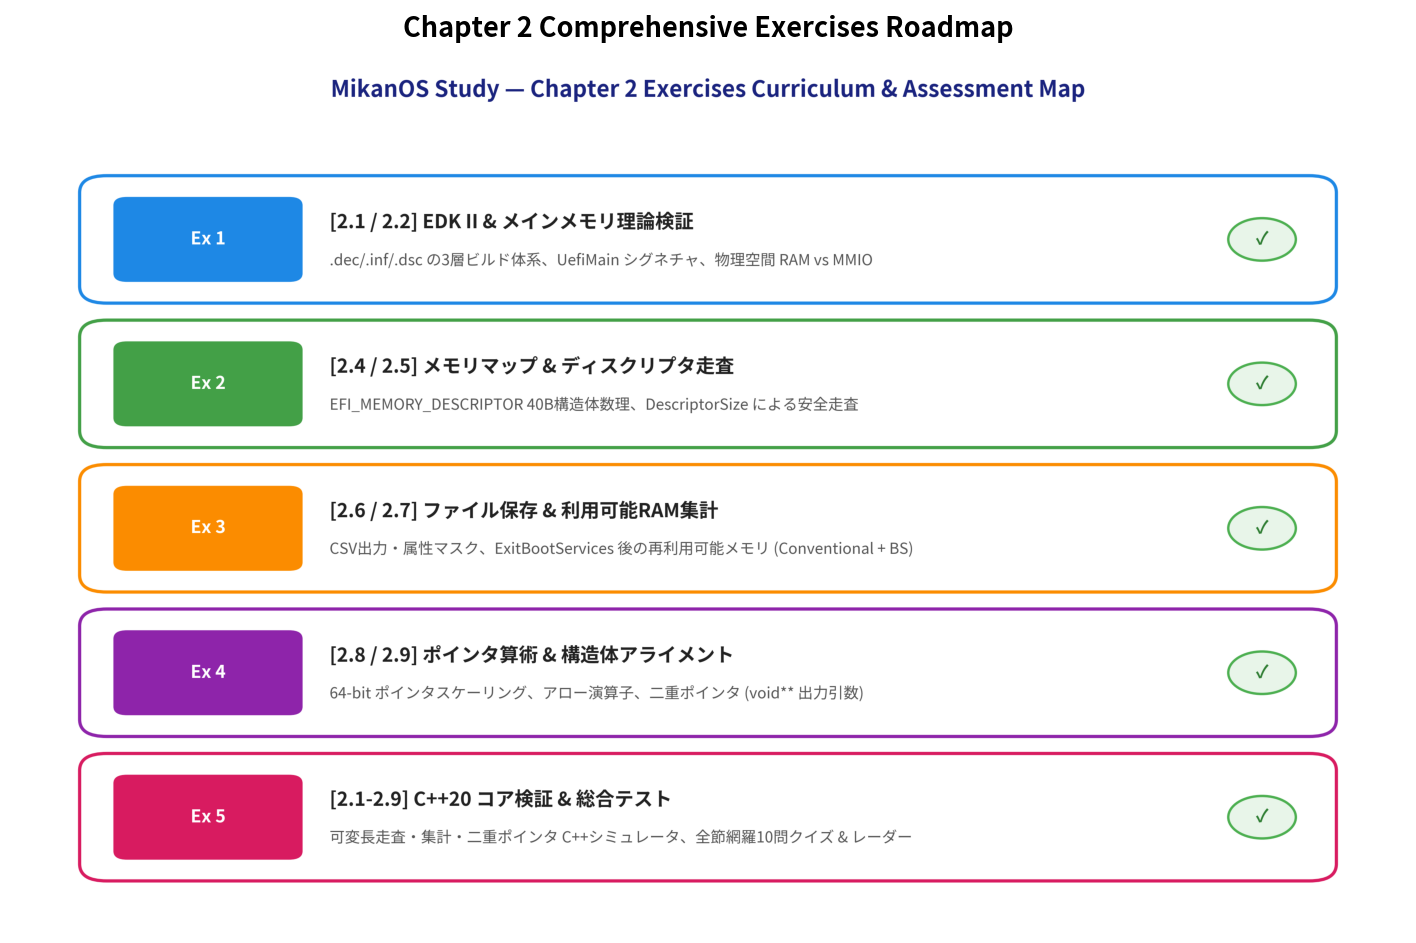

In [2]:
import matplotlib.pyplot as plt
from pathlib import Path
from common import plot_chapter2_exercises_summary

summary_fig = Path("result/fig2_ex1_exercises_summary.png")
plot_chapter2_exercises_summary(summary_fig)

img = plt.imread(str(summary_fig))
plt.figure(figsize=(12, 7.5), dpi=150)
plt.imshow(img)
plt.axis("off")
plt.title("Chapter 2 Comprehensive Exercises Roadmap", fontsize=13, pad=12, fontweight="bold")
plt.show()


---

## 1. 理論・概念の穴埋め演習 (Theory & Architecture Exercises)

### 問題 1-1: EDK II パッケージ設定ファイル (.dec, .inf, .dsc) の役割 (節 2.1)

EDK II のビルドシステムを構成する以下の3つの設定ファイルの役割を、キーワード（`"Declaration"`, `"Module Information"`, `"Platform Description"` など）を含む説明文として辞書 `file_roles` に設定してください：
- `".dec"`: 公開プロトコルや GUID、ヘッダファイルの宣言ファイル (Declaration)
- `".inf"`: 単一モジュールのソースコード一覧や依存関係を定義するファイル (Module Information)
- `".dsc"`: ビルド対象パッケージ全体の構成やライブラリクラスの実体を解決するファイル (Platform Description)


In [3]:
from common import Chapter2TheoryValidator

# === 問題 1-1 解答セル ===
file_roles = {
    ".dec": "Package Declaration: 公開プロトコルやGUID・ヘッダを宣言するファイル",
    ".inf": "Module Information: 単一モジュールのソースコード一覧と依存関係を定義するファイル",
    ".dsc": "Platform Description: ビルド対象パッケージ全体の構成とライブラリインスタンスを解決するファイル",
}

ok, msg = Chapter2TheoryValidator.validate_edk2_files(file_roles)
print(f"判定結果: {'PASS ✅' if ok else 'FAIL ❌'}")
print(msg)
assert ok, "問題 1-1 が不正解です。定義を見直してください。"


判定結果: PASS ✅
正解！EDK IIの3大設定ファイル（.dec, .inf, .dsc）の役割を正確に同定しました。


### 問題 1-2: EFI_MEMORY_DESCRIPTOR 構造体のサイズと自然アライメント (節 2.4)

UEFI仕様書に準拠した 64ビット環境における `EFI_MEMORY_DESCRIPTOR` 構造体のフィールドサイズ（バイト数）およびパディングを辞書 `descriptor_layout` に設定してください：
- `struct_size`: 構造体全体の総バイト数（自然アライメント適用後）
- `type_size`: `Type` フィールド（`UINT32`）のサイズ
- `pad_size`: 8バイトアライメントのための `Type` 直後のパディングサイズ
- `physical_start_size`: `PhysicalStart`（`EFI_PHYSICAL_ADDRESS` = `UINT64`）のサイズ
- `number_of_pages_size`: `NumberOfPages`（`UINT64`）のサイズ
- `attribute_size`: `Attribute`（`UINT64`）のサイズ


In [4]:
# === 問題 1-2 解答セル ===
descriptor_layout = {
    "struct_size": 40,             # 40 bytes (0x28)
    "type_size": 4,                # UINT32
    "pad_size": 4,                 # 4 bytes padding for 8-byte alignment
    "physical_start_size": 8,      # UINT64
    "number_of_pages_size": 8,     # UINT64
    "attribute_size": 8,           # UINT64
}

ok, msg = Chapter2TheoryValidator.validate_memory_descriptor_layout(descriptor_layout)
print(f"判定結果: {'PASS ✅' if ok else 'FAIL ❌'}")
print(msg)
assert ok, "問題 1-2 が不正解です。バイト数を見直してください。"


判定結果: PASS ✅
正解！EFI_MEMORY_DESCRIPTOR 構造体の40バイトレイアウトおよび自然アライメントパディングを正確に定義しました。


### 問題 1-3: ExitBootServices() 後の再利用可能メモリ種別の特定 (節 2.4, 2.7)

UEFI ブートローダが `ExitBootServices()` を完了した後、OS カーネルが**自由な汎用物理メモリ（ヒープやページフレーム等）として再利用できる**メモリ種別（`EFI_MEMORY_TYPE` の列挙名文字列）をリスト `reclaimable_types` に列挙してください。
（※ 注意: `EfiRuntimeServicesCode` や `EfiACPIReclaimMemory` など、OS 稼働中も保持が必要な領域を含めてはいけません）


In [5]:
# === 問題 1-3 解答セル ===
reclaimable_types = [
    "EfiConventionalMemory",      # 元々の空きRAM
    "EfiBootServicesCode",        # ブートサービス完了後に不要となるコード領域
    "EfiBootServicesData",        # ブートサービス完了後に不要となるデータ領域
]

ok, msg = Chapter2TheoryValidator.validate_exit_boot_services_reclaimable(reclaimable_types)
print(f"判定結果: {'PASS ✅' if ok else 'FAIL ❌'}")
print(msg)
assert ok, "問題 1-3 が不正解です。再利用可能な種別を見直してください。"


判定結果: PASS ✅
正解！ExitBootServices完了後にOSが自由に使用できる3大メモリ種別（Conventional, BootServicesCode, BootServicesData）を完璧に特定しました。


### 問題 1-4: 64-bit ポインタ算術とスケーリング加算 (節 2.8)

64ビット（x86-64）環境におけるポインタ変数自体のサイズと、型ごとのポインタ加算（`ptr + 1`）時にアドレス値が何バイト進むかのスケーリング値を辞書 `pointer_arithmetic` に設定してください：
- `pointer_size_bytes`: 64ビット CPU における任意のポインタ変数（`void*`, `char*`, `int*` 等）のメモリ占有バイト数
- `uint32_ptr_add_1_bytes`: `uint32_t* p` に対する `p + 1` が進めるメモリアドレスのバイト数
- `uint64_ptr_add_1_bytes`: `uint64_t* p` に対する `p + 1` が進めるメモリアドレスのバイト数


In [6]:
# === 問題 1-4 解答セル ===
pointer_arithmetic = {
    "pointer_size_bytes": 8,       # すべてのポインタは一律 8バイト (64ビット)
    "uint32_ptr_add_1_bytes": 4,   # sizeof(uint32_t) = 4バイト進む
    "uint64_ptr_add_1_bytes": 8,   # sizeof(uint64_t) = 8バイト進む
}

ok, msg = Chapter2TheoryValidator.validate_pointer_arithmetic(pointer_arithmetic)
print(f"判定結果: {'PASS ✅' if ok else 'FAIL ❌'}")
print(msg)
assert ok, "問題 1-4 が不正解です。スケーリング数理を見直してください。"


判定結果: PASS ✅
正解！64ビットポインタサイズ（8B）と型スケーリング加算の数理を正確に算出しました。


---

## 2. 実践 Python 実装演習 (Practical Verification Exercises)

### 問題 2-1: 可変長 DescriptorSize によるメモリマップ走査デコーダ (節 2.5)

ファームウェアから返されたメモリマップバッファ（`bytes`）と、各ディスクリプタのサイズ `desc_size`（例: 48バイト）を受け取り、各ディスクリプタを**バイト単位オフセット加算**で安全に走査して、`(Type, PhysicalStart, NumberOfPages)` のタプルリストを返す関数 `scan_memory_map_buffer` を完成させてください。

- 先頭 4バイト: `Type`（32-bit uint, little-endian）
- オフセット 8〜15: `PhysicalStart`（64-bit uint, little-endian）
- オフセット 24〜31: `NumberOfPages`（64-bit uint, little-endian）
- 次のディスクリプタのアドレス: 現在のオフセットに `desc_size` を加算


In [7]:
import struct

def scan_memory_map_buffer(buffer: bytes, desc_size: int) -> list[tuple[int, int, int]]:
    """Scan memory map buffer with variable-length descriptor size and extract key fields."""
    results = []
    num_descriptors = len(buffer) // desc_size
    for i in range(num_descriptors):
        offset = i * desc_size
        desc_bytes = buffer[offset:offset + desc_size]
        # Type: uint32 at offset 0
        mem_type = struct.unpack_from("<I", desc_bytes, 0)[0]
        # PhysicalStart: uint64 at offset 8
        phys_start = struct.unpack_from("<Q", desc_bytes, 8)[0]
        # NumberOfPages: uint64 at offset 24
        num_pages = struct.unpack_from("<Q", desc_bytes, 24)[0]
        results.append((mem_type, phys_start, num_pages))
    return results

# === 自動テスト ===
# 48バイトの可変長ディスクリプタを2件模擬
dummy_desc1 = struct.pack("<IIQQQQQ", 7, 0, 0x100000, 0x100000, 256, 0xF, 0) # Conventional (Type 7), 256 pages (1MiB)
dummy_desc2 = struct.pack("<IIQQQQQ", 3, 0, 0x200000, 0x200000, 128, 0xF, 0) # BootServicesCode (Type 3), 128 pages
test_buf = dummy_desc1[:48] + dummy_desc2[:48]

entries = scan_memory_map_buffer(test_buf, 48)
print("デコード結果:")
for idx, (t, p, pages) in enumerate(entries):
    print(f"  [{idx}] Type: {t}, PhysStart: 0x{p:X}, Pages: {pages} ({pages * 4} KiB)")

assert len(entries) == 2
assert entries[0] == (7, 0x100000, 256)
assert entries[1] == (3, 0x200000, 128)
print("✅ 問題 2-1: 可変長メモリマップ走査テスト合格！")


デコード結果:
  [0] Type: 7, PhysStart: 0x100000, Pages: 256 (1024 KiB)
  [1] Type: 3, PhysStart: 0x200000, Pages: 128 (512 KiB)
✅ 問題 2-1: 可変長メモリマップ走査テスト合格！


### 問題 2-2: メモリマップ CSV パーサ & 利用可能空き RAM 集計 (節 2.7)

書籍のブートローダが出力する `memmap` CSV ファイルのテキスト行（カンマ区切りの文字列）をパースし、**ExitBootServices() 完了後に OS が利用可能となる空き RAM（Type 3: BootServicesCode, Type 4: BootServicesData, Type 7: ConventionalMemory）の総バイト数** を算出する関数 `calc_usable_ram_from_csv` を完成させてください。

※ 1ページは 4,096バイト（4KiB）です。


In [8]:
def calc_usable_ram_from_csv(csv_text: str) -> int:
    """Parse memmap CSV and calculate total usable bytes after ExitBootServices()."""
    usable_types = {3, 4, 7}  # BS Code, BS Data, Conventional
    total_pages = 0

    lines = csv_text.strip().splitlines()
    for line in lines:
        line = line.strip()
        if not line or line.startswith("Index") or line.startswith("#"):
            continue
        parts = [p.strip() for p in line.split(",")]
        if len(parts) < 5:
            continue
        
        # Format: Index, Type, Type(name), PhysicalStart, NumberOfPages, Attribute
        raw_type = parts[1]
        mem_type = int(raw_type, 16) if raw_type.startswith("0x") else int(raw_type)
        
        raw_pages = parts[4]
        pages = int(raw_pages, 16) if raw_pages.startswith("0x") else int(raw_pages)
        
        if mem_type in usable_types:
            total_pages += pages

    return total_pages * 4096

# === 自動テスト ===
sample_csv = """Index, Type, Type(name), PhysicalStart, NumberOfPages, Attribute
0, 3, EfiBootServicesCode, 0x0000000000100000, 128, 0x0000000F
1, 4, EfiBootServicesData, 0x0000000000200000, 256, 0x0000000F
2, 7, EfiConventionalMemory, 0x0000000000400000, 1024, 0x0000000F
3, 11, EfiMemoryMappedIO, 0x00000000FE000000, 512, 0x00000001
"""

usable_bytes = calc_usable_ram_from_csv(sample_csv)
usable_mib = usable_bytes / (1024 * 1024)
print(f"集計結果: 利用可能メモリ = {usable_mib:.2f} MiB ({usable_bytes} バイト)")

expected_pages = 128 + 256 + 1024  # 1408 pages
expected_bytes = expected_pages * 4096  # 5,767,168 bytes = 5.5 MiB
assert usable_bytes == expected_bytes, f"期待値 {expected_bytes}, 計算結果 {usable_bytes}"
print("✅ 問題 2-2: メモリマップ CSV 集計テスト合格！")


集計結果: 利用可能メモリ = 5.50 MiB (5767168 バイト)
✅ 問題 2-2: メモリマップ CSV 集計テスト合格！


### 問題 2-3: 構造体の自然アライメント・パディング計算機 (節 2.9)

x86-64 の C/C++ において、以下の構造体のメモリレイアウトを解析してください：
```cpp
struct Example {
    uint8_t  a;    // 1 byte
    uint32_t b;    // 4 bytes
    uint16_t c;    // 2 bytes
};
```
各メンバの自然アライメント（その型のサイズ境界に配置される規則）に従った場合：
- `a` 直後に挿入されるパディングバイト数 (`pad_after_a`)
- `c` 直後に挿入され構造体全体のサイズを最大アライメント（4バイト）の倍数に整列するためのパディング (`pad_after_c`)
- 構造体全体のサイズ `total_size`（`sizeof(Example)`）
を辞書 `alignment_result` に設定してください。


In [9]:
# === 問題 2-3 解答セル ===
alignment_result = {
    "total_size": 12,       # 1B (a) + 3B (pad) + 4B (b) + 2B (c) + 2B (pad) = 12B
    "pad_after_a": 3,       # uint32_t b の 4バイト境界整列のため
    "pad_after_c": 2,       # 構造体全体を 4バイトの倍数に整列するため
}

ok, msg = Chapter2TheoryValidator.validate_struct_alignment(alignment_result)
print(f"判定結果: {'PASS ✅' if ok else 'FAIL ❌'}")
print(msg)
assert ok, "問題 2-3 が不正解です。アライメント計算を見直してください。"


判定結果: PASS ✅
正解！自然アライメント規則に基づくパディングと構造体総サイズ（12B）を正確に計算しました。


---

## 3. C++20 スタンドアロン検証コードの実行 (C++20 Systems Verification)

本リポジトリでは、第2章で学んだコア理論をホスト側 C++20（`g++ -std=c++20 -O2`）で直接検証可能なスタンドアロン検証バイナリ [`src/ch02/os_chapter2_exercises.cpp`](../src/ch02/os_chapter2_exercises.cpp) として提供しています。

このプログラムは以下の4大低レイヤシステム機構を直接実証します：
1. **EFI_MEMORY_DESCRIPTOR の 40バイト自然アライメント**
2. **可変長 DescriptorSize（48バイト等）による安全なバイトポインタ走査**
3. **ExitBootServices() 後の再利用可能 RAM（Conventional + BS Code/Data）の合算**
4. **二重ポインタ（`T**`）による関数外ポインタのアドレス書き戻し**

以下のセルを実行して、C++20 検証コードを対話型コンパイル＆実行してください。


In [10]:
import subprocess

# C++20 スタンドアロン検証バイナリのコンパイル & 実行
cmd_build = [
    "g++", "-std=c++20", "-O2", "-Wall", "-Wextra",
    "../src/ch02/os_chapter2_exercises.cpp",
    "-o", "../build/bin/ch02_os_chapter2_exercises"
]
subprocess.run(cmd_build, check=True)

# 実行
result = subprocess.run(["../build/bin/ch02_os_chapter2_exercises", "--test"], capture_output=True, text=True, check=True)
print(result.stdout)


 MikanOS Chapter 2 Comprehensive Exercises (C++20 Verify)

[Ex 1] Verifying EFI_MEMORY_DESCRIPTOR Struct Layout...
  - Packed descriptor size:  36 bytes
  - Aligned descriptor size: 40 bytes (matches UEFI spec)
  ✓ Verified descriptor layout & 40-byte natural alignment!

[Ex 2] Simulating Safe Memory Map Scanning (DescriptorSize = 48 bytes)...
  - Total descriptors: 4
  - Usable RAM after ExitBootServices: 2 MiB (2621440 bytes)
  ✓ Verified variable-length descriptor traversal and RAM reclamation!

[Ex 3] Verifying Natural Alignment & Padding Mathematics...
  - MixedStruct sizeof: 12 bytes (aligned to 4 bytes)
  ✓ Verified natural alignment offsets!

[Ex 4] Verifying Double Pointer (T**) Address Reassignment Pattern...
  - Successfully assigned protocol address: 0x649ed2776160
  - Protocol Name: EFI_SIMPLE_FILE_SYSTEM_PROTOCOL (ID: 42)
  ✓ Verified double pointer out-parameter semantics!

🎉 ALL CHAPTER 2 C++20 EXERCISES PASSED SUCCESSFULLY!
Running in --test mode: verification complete

---

## 4. 第2章 総合理解度チェックテスト (Chapter 2 Comprehensive Quiz)

第2章の全9節（2.1〜2.9）から厳選された **10問の4択問題** です。
以下のセルを実行して設問を確認し、解答を入力して自己採点を行ってください。


In [11]:
from common import Chapter2Quiz

quiz = Chapter2Quiz()

print(f"======================================================================")
print(f" 第2章 EDK II入門とメモリマップ 総合理解度チェックテスト (全 {len(quiz.questions)} 問)")
print(f"======================================================================\n")

for q in quiz.questions:
    print(f"【問 {q.question_id}】 (節 {q.section}: {q.topic})")
    print(f"{q.question}")
    for idx, opt in enumerate(q.options):
        print(f"  ({idx}) {opt}")
    print()


 第2章 EDK II入門とメモリマップ 総合理解度チェックテスト (全 10 問)

【問 1】 (節 2.1: EDK II パッケージ設定ファイル (.dec, .dsc, .inf))
EDK II パッケージにおける .dec, .inf, .dsc の3つの設定ファイルの役割の組み合わせとして正しいものはどれか？
  (0) .dec: バイナリ実行ファイル, .inf: パッケージ全体ビルド構成, .dsc: 公開インターフェース宣言
  (1) .dec: 公開プロトコル/GUID等の宣言 (Declaration), .inf: 単一モジュールのソース・依存関係定義 (Information), .dsc: ビルド対象パッケージ全体の構成・ライブラリ解決 (Description)
  (2) .dec: リンカスクリプト, .inf: Makefile生成ルール, .dsc: ドキュメント定義
  (3) .dec: 単一コンポーネント定義, .inf: パッケージ全体記述, .dsc: 公開ヘッダ宣言

【問 2】 (節 2.2: UefiMain シグネチャとプリプロセッサ)
EDK IIブートローダのエントリポイント UefiMain のシグネチャと、プリプロセッサ #include の動作として正しいものはどれか？
  (0) int main(int argc, char** argv) であり、#include は実行時に共有ライブラリを動的ロードする
  (1) EFI_STATUS EFIAPI UefiMain(EFI_HANDLE ImageHandle, EFI_SYSTEM_TABLE *SystemTable) であり、#include は指定されたヘッダファイルの内容をコンパイル前にその位置へテキスト展開する
  (2) void UefiMain(void) であり、#include はバイナリオブジェクトをリンクする
  (3) EFI_STATUS UefiMain(EFI_BOOT_SERVICES *BS) であり、#include は仮想関数テーブルを自動生成する

【問 3】 (節 2.3: メインメモリ物理アドレス空間とMMIO)
現代の x86-64 アーキテクチャにおける物理アドレス空間と MMIO

In [12]:
# === 解答入力セル ===
# 各問の選択肢番号 (0, 1, 2, 3) を辞書に入力してください
my_answers = {
    1: 1,  # .dec: 宣言, .inf: モジュール情報, .dsc: パッケージ全体構成
    2: 1,  # UefiMain シグネチャとプリプロセッサ #include のテキスト展開
    3: 1,  # 物理アドレス空間のスパース性と MMIO / PCIホール
    4: 1,  # EFI_MEMORY_DESCRIPTOR 40Bレイアウトと自然アライメント
    5: 1,  # GetMemoryMap() の EFI_BUFFER_TOO_SMALL と MapKey
    6: 1,  # DescriptorSize による可変長ディスクリプタのバイト走査
    7: 1,  # ファイル保存と属性ビットマスク (& 0xffffflu)
    8: 2,  # ExitBootServices 後の再利用可能メモリ (Conventional + BS Code/Data)
    9: 1,  # 64-bit ポインタサイズ (8B) とポインタ算術スケーリング (sizeof(T))
    10: 1, # アロー演算子 -> と二重ポインタ (void** 出力引数パターン)
}

eval_result = quiz.evaluate(my_answers)

print("=" * 60)
print(f"採点結果: {eval_result['correct_count']} / {eval_result['total_questions']} 正解 (得点率: {eval_result['percentage']:.1f}%)")
print(f"合否判定: {'合格 (PASSED 🎉)' if eval_result['passed'] else '不合格 (FAILED ⚠️ 要復習)'}")
print("=" * 60)

for d in eval_result['details']:
    status = "正解 ⭕" if d['is_correct'] else "不正解 ❌"
    print(f"問 {d['question_id']} [{d['section']}]: {status} (選択: {d['user_answer']} / 正解: {d['correct_answer']})")
    print(f"  解説: {d['explanation']}\n")

assert eval_result['passed'], "演習目標の 80% に届きませんでした。解説を確認して再挑戦してください。"


採点結果: 10 / 10 正解 (得点率: 100.0%)
合否判定: 合格 (PASSED 🎉)
問 1 [2.1]: 正解 ⭕ (選択: 1 / 正解: 1)
  解説: EDK IIでは、.dec (Package Declaration) が公開プロトコルやGUID・ヘッダを宣言し、.inf (Module Information) が各モジュールのソースコードや依存ライブラリクラスを定義し、.dsc (Platform Description) が実際にビルドするモジュール群と各ライブラリクラスの実体インスタンスのマッピングを統合管理します。

問 2 [2.2]: 正解 ⭕ (選択: 1 / 正解: 1)
  解説: EDK IIアプリケーションのエントリポイントは UEFI呼び出し規約修飾子 EFIAPI を持つ EFI_STATUS EFIAPI UefiMain(EFI_HANDLE ImageHandle, EFI_SYSTEM_TABLE *SystemTable) です。またC言語のプリプロセッサ #include は、指定ヘッダファイルをその場にそのままテキスト展開する単純な文字列置換機構です。

問 3 [2.3]: 正解 ⭕ (選択: 1 / 正解: 1)
  解説: 物理アドレス空間は物理RAMだけでなく、GPUやxHCI等のハードウェア制御用レジスタ（MMIO）やPCIデバイス用予約空間（PCIホール）、ROM領域が混在して配置されており、物理RAMは飛び飛び（スパース）に配置されます。MMIO領域はMOV等の通常メモリアクセス命令で直接制御できます。

問 4 [2.4]: 正解 ⭕ (選択: 1 / 正解: 1)
  解説: 64ビット環境において EFI_MEMORY_DESCRIPTOR は Type (UINT32: 4バイト) の直後に 8バイトアライメントのための 4バイトパディングが挿入され、続く PhysicalStart (8B), VirtualStart (8B), NumberOfPages (8B), Attribute (8B) と合わせて合計 40バイト（0x28バイト）となります。

問 5 [2.5]: 正解 ⭕ (選択: 1 / 正解: 1)
  解説: GetMemoryMap() は提供バ

---

## 5. 理解度レーダーチャートの可視化 & 総括 (Mastery Radar & Wrap-up)

以下のセルを実行して、第2章の全9節に対するあなたの理解度レーダーチャートを生成・可視化します。


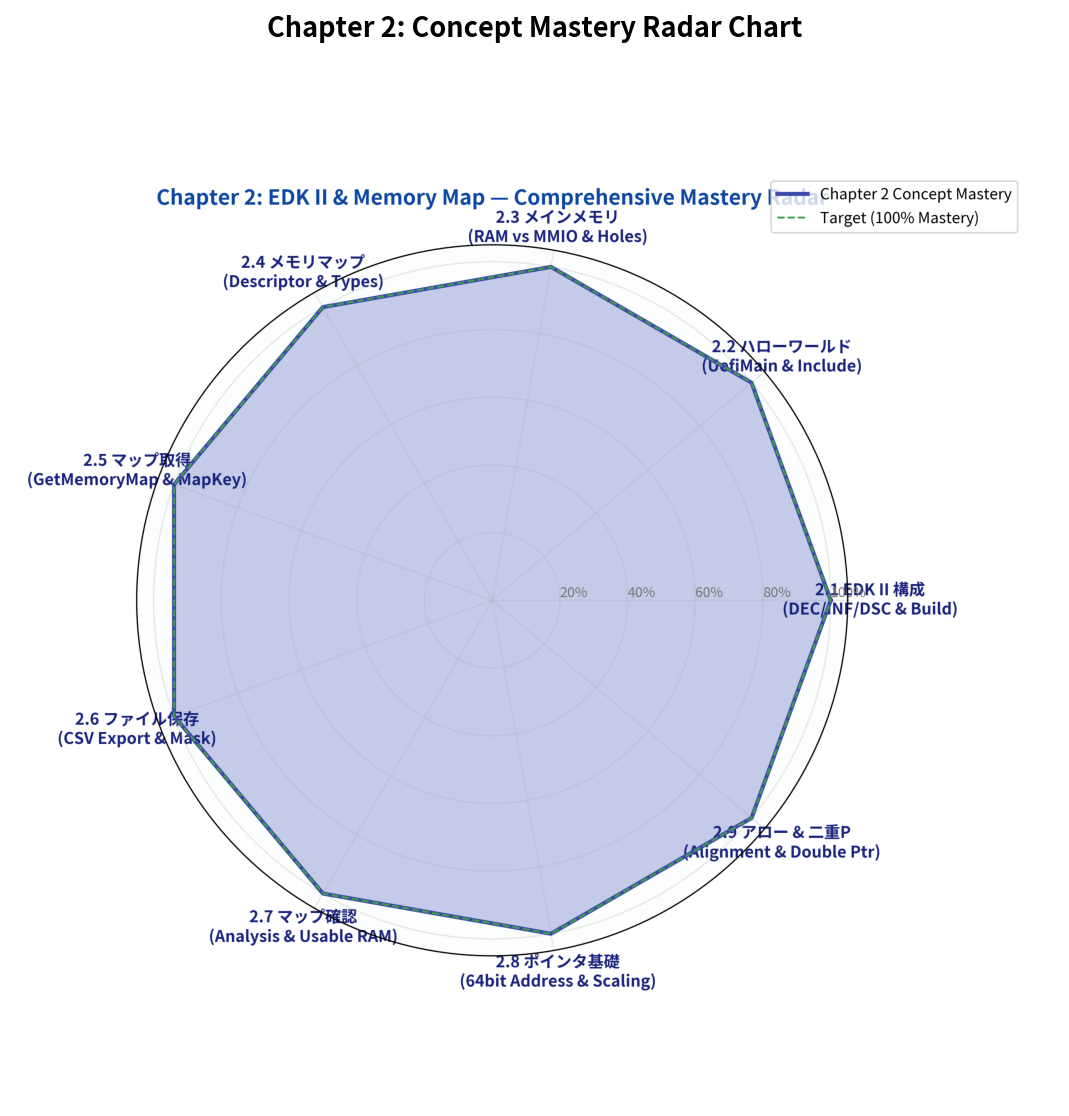

In [13]:
from common import plot_chapter2_mastery_radar

radar_fig = Path("result/fig2_ex2_ch2_mastery_radar.png")
plot_chapter2_mastery_radar(radar_fig, eval_result['mastery_rates'])

img_radar = plt.imread(str(radar_fig))
plt.figure(figsize=(9, 9), dpi=150)
plt.imshow(img_radar)
plt.axis("off")
plt.title("Chapter 2: Concept Mastery Radar Chart", fontsize=13, pad=12, fontweight="bold")
plt.show()


---

## 🏆 第2章 総括と第3章への展望

おめでとうございます！これで第2章「**EDK II入門とメモリマップ**」の全9節と演習問題をすべて完遂しました。

### 本章で身につけた武器・アーキテクチャ理解
1. **EDK II 開発エコシステムの習得**:
   - `.dec`（公開仕様の宣言）、`.inf`（モジュール単位のビルド定義）、`.dsc`（プラットフォーム統合構成）の3層構造をマスターし、大規模な UEFI アプリケーション開発基盤を手に入れました。
2. **物理アドレス空間とメモリマップの完全把握**:
   - DRAM だけではないスパースな物理アドレス空間（MMIO や PCI ホール）の構造を数理的に把握し、`gBS->GetMemoryMap()` による `EFI_MEMORY_DESCRIPTOR` の取得、`MapKey` によるメモリ状態の整合性保証、および可変長 `DescriptorSize` による安全なバイトポインタ走査技術を獲得しました。
3. **OSブートのメモリ再利用ライフサイクル**:
   - `ExitBootServices()` 完了後に、ファームウェアから解放される `EfiBootServicesCode` と `EfiBootServicesData` を空き RAM（`EfiConventionalMemory`）とともに回収して、OS のヒープやページテーブル空間として再利用する重要ロジックを導出しました。
4. **低レイヤ C/C++ ポインタ・アライメントの極意**:
   - 64ビット CPU におけるポインタのサイズ不変性（8バイト）、`ptr + 1` の型スケーリング（`sizeof(T)`）、構造体の自然アライメントとパディング数理、そして関数外のポインタ変数を書き換えてアドレスを戻すための二重ポインタ（`void**`）の仕組みを完全に体得しました。

---

### 次なるステージ: 第3章「画面表示の練習とブートローダ」

第3章からは、いよいよ画面描画の扉が開きます！
- **QEMU モニタと x86-64 レジスタ**: 仮想ハードウェアのレジスタ（`RAX`〜`R15`, `RIP`, `RSP`, `CR0`〜`CR4`）を直視し、ベアメタル環境を掌握します。
- **初めてのカーネル (`osbook_day03a`)**: ブートローダがカーネルの ELF 実行ファイルをメモリへロードし、`ExitBootServices()` を経てカーネルのエントリポイントへジャンプする歴史的瞬間を迎えます。System V ABI の「レッドゾーン（128バイト）」の罠と `-mno-red-zone` の必然性も徹底解明します。
- **GOP フレームバッファによるピクセル描画 (`osbook_day03b`〜`day03c`)**: UEFI GOP (*Graphics Output Protocol*) から取得した VRAM ベースアドレスへ直接カラーピクセルを書き込み、画面上に幾何学模様を描き出します。

第2章で鍛え上げたメモリ制御とポインタの武器を手に、第3章「**画面表示の練習とブートローダ**」へ進みましょう！
